# Chained vs direct: does starting from the previous split help?

| Que_v2 job | Thesis job | Split    | Start                                  | wandb      |
|------------|------------|----------|----------------------------------------|------------|
| 7          | 1          | asl300   | K400 (direct)                          | `etgbtqd7` |
| 16         | 4          | asl300   | job 6's asl100 `best.pth` (chained)    | `0ccnw708` |
| 8          | 1          | asl1000  | K400 (direct), cancelled after 3 epochs | `r2ab8k9u` |
| 17         | 4          | asl1000  | job 16's `best.pth` (chained)          | `3ro3fhtf` |

All four are `MViTv2_S_16x4_e`, seed 42, on the plain 0-based splits, with the sweep's config
`5mzfq88e` (`src/configfiles/thesis_final/MViTv2_S_16x4_e_5mzfq88e*.toml`, max 25 epochs). The
direct asl1000 run stayed at chance (val accuracy 0.26% every epoch) and was cancelled: its
inverted learning rates (backbone 5.1e-4, head 5.2e-5) were
tuned on asl100 from K400 and don't transfer. Validation accuracy per epoch, for the thesis's
"Transferring knowledge from one split to another" ablation (asked 2026-11-06). Split names:
[WLASL_info.md](../../info/WLASL_info.md).

In [1]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import wandb
from src.results import get_asset_path, get_stash_path, load_json
from src.visualise2 import LINE_PALETTE, plot_loss_curves, save_fig, set_thesis_style

set_thesis_style()

## Setup

In [2]:
ENTITY = 'ljgoodall2001-rhodes-university'
RUNS = { # panel -> {series: (wandb project, run id)}
    'WLASL-300': {'direct': ('WLASL-300', 'etgbtqd7'), 'chained': ('WLASL-300', '0ccnw708')},
    'WLASL-1000': {'direct': ('WLASL-1000', 'r2ab8k9u'), 'chained': ('WLASL-1000', '3ro3fhtf')},
}
SERIES_LABELS = {'direct': 'Direct from K400', 'chained': 'Chained from the previous split'}
stash_path = get_stash_path('MViTv2_S_16x4_e_5mzfq88e_', base_name='val_history')


def fetch_val_history(project: str, run_id: str) -> list[dict[str, float]]:
    """One `{'epoch', 'val_loss', 'val_acc'}` row per validated epoch of a wandb run."""
    run = wandb.Api(timeout=60).run(f'{ENTITY}/{project}/{run_id}')
    return [
        {'epoch': row['Epoch'], 'val_loss': row['Loss/Val'], 'val_acc': row['Accuracy/Val']}
        for row in run.scan_history(keys=['Epoch', 'Loss/Val', 'Accuracy/Val'])
    ]


# from src.results import stash_json
# stash_json(
#     {panel: {s: fetch_val_history(*r) for s, r in series.items()} for panel, series in RUNS.items()},
#     stash_path, indent=1,
# )
history: dict[str, dict[str, list[dict[str, float]]]] = load_json(stash_path)

## Validation accuracy and loss at a few epochs

In [3]:
for panel, series in history.items():
    for name, rows in series.items():
        best = min(rows, key=lambda r: r['val_loss'])
        firsts = ', '.join(f"{r['val_acc']:.2f}" for r in rows[:5])
        print(f"{panel} {name}: {len(rows)} epochs; val acc epochs 1-5: {firsts}; "
              f"best val loss {best['val_loss']:.4f} at epoch {best['epoch']}")

WLASL-300 direct: 25 epochs; val acc epochs 1-5: 1.33, 6.88, 15.54, 29.52, 39.51; best val loss 0.7530 at epoch 25
WLASL-300 chained: 25 epochs; val acc epochs 1-5: 30.30, 35.18, 48.95, 55.94, 54.27; best val loss 0.8651 at epoch 25
WLASL-1000 direct: 3 epochs; val acc epochs 1-5: 0.26, 0.26, 0.26; best val loss 6.8587 at epoch 2
WLASL-1000 chained: 25 epochs; val acc epochs 1-5: 30.52, 30.82, 41.16, 47.03, 49.35; best val loss 1.3272 at epoch 25


## Figure

Two panels, 15 cm wide (the thesis's `\linewidth`), no title, legend below.

PosixPath('/home/luke/Code/SLR/src/results/outputs/chained_vs_direct/val_acc_chained_vs_direct_MViTv2_S_16x4_e_5mzfq88e.pdf')

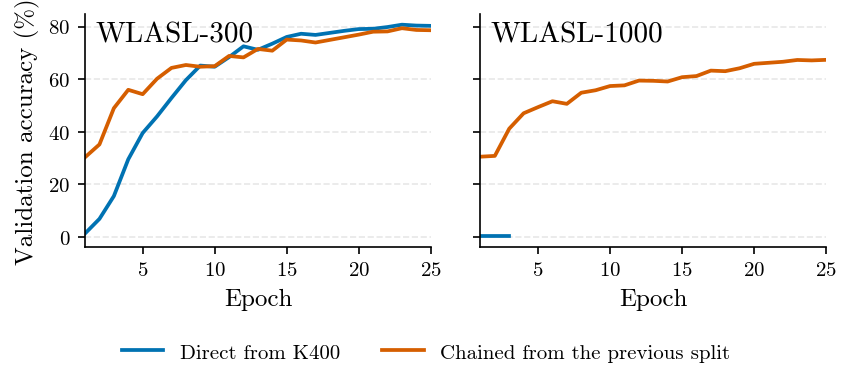

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(5.9, 2.6), sharey=True)
palette = [LINE_PALETTE[0], LINE_PALETTE[1]]
for ax, (panel, series) in zip(axes, history.items(), strict=True):
    for name, colour in zip(series, palette, strict=True):
        rows = series[name]
        plot_loss_curves(
            [r['epoch'] for r in rows], {name: [r['val_acc'] for r in rows]},
            palette=[colour], xlabel='Epoch', ax=ax,
        )
    ax.get_legend().remove()
    ax.set_xlim(1, 25)
    ax.text(0.03, 0.97, panel, transform=ax.transAxes, va='top')
axes[0].set_ylabel('Validation accuracy (%)')
handles = [Line2D([], [], color=c, linewidth=1.8) for c in palette]
fig.legend(handles, [SERIES_LABELS[s] for s in ('direct', 'chained')], loc='lower center',
           ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.08, 1, 1))
save_fig(fig, get_asset_path('val_acc_chained_vs_direct', 'MViTv2_S_16x4_e_5mzfq88e', 'chained_vs_direct'))